In [1]:
import importlib
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import nn
import plotting

importlib.reload(nn)
importlib.reload(plotting)

from nn import NeuralNetwork, train, train_classification, cross_entropy, run_cv_ffnn
from data import load_cv_data_fashion_mnist, one_hot, CLASS_NAMES
from plotting import plot_heatmap, plot_confusion
from optimizers import Adam, RMSprop
from metrics import accuracy, confusion

project_root = Path.cwd().parent if Path.cwd().name == "code" else Path.cwd()
figures_dir = project_root / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

In [2]:
# Import data ready for cross validation
(Xtr, ytr), (Xtest, ytest) = load_cv_data_fashion_mnist()

In [3]:
# Example code of how to use CV function. Here used for hyperparameter search of learning rate
learning_rates = [1e-2, 1e-3, 1e-4]

for lr in learning_rates:
    loss, best_epoch = run_cv_ffnn(
        Xtr, ytr,
        lr=lr,
        hidden_layers=2,
        nodes=50,
        activations="relu",
        epochs=30
    )

    print(f"LR={lr}: val loss={loss:.4f}, best epoch={best_epoch}")

Epoch 1: mean val loss = 0.5825
Epoch 2: mean val loss = 0.5398
Epoch 3: mean val loss = 0.5123
Epoch 4: mean val loss = 0.5118
Epoch 5: mean val loss = 0.5004
Epoch 6: mean val loss = 0.5147
Epoch 7: mean val loss = 0.4873
Epoch 8: mean val loss = 0.5198
Epoch 9: mean val loss = 0.5145
Epoch 10: mean val loss = 0.5088
Stopped at epoch 10, best epoch: 7
LR=0.01: val loss=0.4873, best epoch=7
Epoch 1: mean val loss = 0.5526
Epoch 2: mean val loss = 0.5002
Epoch 3: mean val loss = 0.4701
Epoch 4: mean val loss = 0.4551
Epoch 5: mean val loss = 0.4440
Epoch 6: mean val loss = 0.4490
Epoch 7: mean val loss = 0.4300
Epoch 8: mean val loss = 0.4362
Epoch 9: mean val loss = 0.4259
Epoch 10: mean val loss = 0.4259
Epoch 11: mean val loss = 0.4371
Epoch 12: mean val loss = 0.4374
Stopped at epoch 12, best epoch: 9
LR=0.001: val loss=0.4259, best epoch=9
Epoch 1: mean val loss = 1.1062
Epoch 2: mean val loss = 0.8001
Epoch 3: mean val loss = 0.6826
Epoch 4: mean val loss = 0.6233
Epoch 5: mean v

In [11]:
model = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
optimizer = Adam(learning_rate=0.001)
history=train(model, optimizer, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

In [12]:
model2 = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
optimizer2 = RMSprop(learning_rate=0.001)
history2=train(model2, optimizer2, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

In [13]:
#ADAM
y_pred = model.predict(x_val)
print(x_train.shape, x_val.shape, x_test.shape, np.bincount(y_test))
print(f"Validation accuracy: {accuracy(y_val, y_pred):.4f}")
print(f"Cross entropy start: {history['train'][0]:.4f}")
print(f"Cross entropy end: {history['train'][-1]:.4f}")

(50000, 784) (10000, 784) (10000, 784) [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]
Validation accuracy: 0.8966
Cross entropy start: 0.4554
Cross entropy end: 0.1594


In [14]:
#RMSprop
y_pred2 = model2.predict(x_val)
print(f"Validation accuracy: {accuracy(y_val, y_pred2):.4f}")
print(f"Cross entropy start: {history2['train'][0]:.4f}")
print(f"Cross entropy end: {history2['train'][-1]:.4f}")
print(f"Training cross-entropy, siste epoch: {history2['train'][-1]:.4f}")
print(f"Lowest validation loss: {min(history2['val']):.4f}")
print(f"Best epoch: {np.argmin(history2['val']) + 1}")

Validation accuracy: 0.8873
Cross entropy start: 0.5364
Cross entropy end: 0.1717
Training cross-entropy, siste epoch: 0.1717
Lowest validation loss: 0.3174
Best epoch: 21


Lowest validation epoch at epoch:18
Lowest validation loss:0.30248124719322916


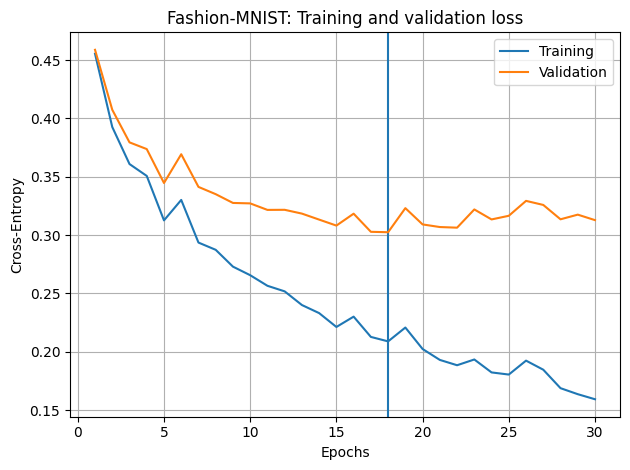

In [15]:
epochs = range(1, len(history["train"]) + 1)
best_epoch = np.argmin(history["val"]) + 1
print(f"Lowest validation epoch at epoch:{best_epoch}")
print(f"Lowest validation loss:{min(history['val'])}")
plt.plot(epochs, history["train"], label="Training")
plt.axvline(int(best_epoch), label="")
plt.plot(epochs, history["val"], label="Validation")
plt.title("Fashion-MNIST: Training and validation loss")
plt.grid()
plt.xlabel("Epochs")
plt.ylabel("Cross-Entropy")
plt.legend()
plt.tight_layout()
plt.gcf().savefig(figures_dir / "ffnn_initial_training_validation_loss.pdf", bbox_inches="tight")
plt.show()

Diffrent learning rates

In [16]:
learning_rates = [1e-4, 1e-3, 1e-2]
history_lr = {}
print(f"gamma | minimum validation loss| Best epoch| Validation accuracy")
for gamma in learning_rates:
    model_lr = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
    optimizer_lr = Adam(learning_rate=gamma)
    history = train(model_lr, optimizer_lr, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
    history_lr[gamma] = history
    best_epoch = np.argmin(history["val"]) + 1
    val_acc = np.mean(model_lr.predict(x_val)==y_val)
    print(f"{gamma:g} & {min(history['val']):.4f} & "
          f"{best_epoch} & {val_acc:.4f}" + r"\\")

gamma | minimum validation loss| Best epoch| Validation accuracy
0.0001 & 0.3638 & 30 & 0.8726\\
0.001 & 0.3025 & 18 & 0.8966\\
0.01 & 0.3489 & 10 & 0.8788\\


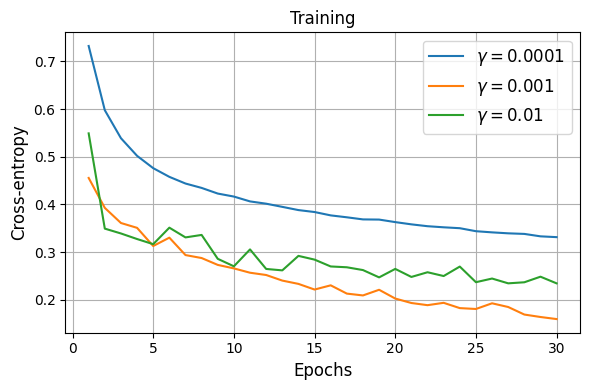

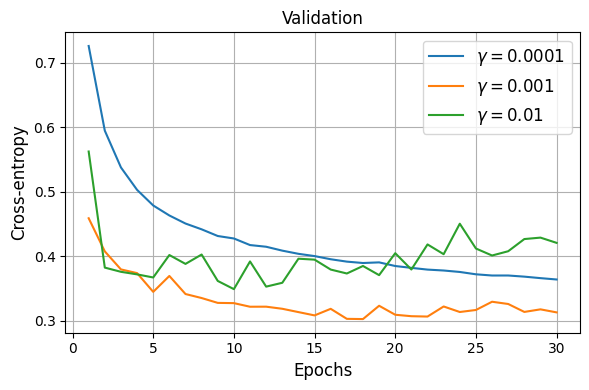

In [17]:
#Adam
fig, ax = plt.subplots(figsize=(6, 4))
for gamma, hist in history_lr.items():
    epoch = np.arange(1, len(hist["train"]) + 1)
    ax.plot(epoch, hist["train"], label=rf"$\gamma = {gamma:g}$")

ax.set_title("Training", fontsize=12)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Cross-entropy", fontsize=12)
ax.legend(fontsize=12)
ax.grid()
fig.tight_layout()
fig.savefig(figures_dir / "ffnn_adam_learning_rates_training.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for gamma, hist in history_lr.items():
    epoch = np.arange(1, len(hist["train"]) + 1)
    ax.plot(epoch, hist["val"], label=rf"$\gamma = {gamma:g}$")

ax.set_title("Validation", fontsize=12)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Cross-entropy", fontsize=12)
ax.legend(fontsize=12)
ax.grid()
fig.tight_layout()
fig.savefig(figures_dir / "ffnn_adam_learning_rates_validation.pdf", bbox_inches="tight")
plt.show()

In [18]:
best_lr = min(history_lr, key=lambda gamma: min(history_lr[gamma]['val']))
print(f"Best learning rate (Adam): {best_lr}")
print(f"Minimum validation loss: {min(history_lr[best_lr]['val']):.4f}")

Best learning rate (Adam): 0.001
Minimum validation loss: 0.3025


In [19]:
#RMSprop
learning_rates = [1e-4, 1e-3, 1e-2]
history_lrr = {}
print(f"gamma | minimum validation loss| Best epoch| Validation accuracy")
for gamma in learning_rates:
    model_lrr = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
    optimizer_lrr = RMSprop(learning_rate=gamma)
    history=train(model_lrr, optimizer_lrr, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
    history_lrr[gamma] = history
    best_epoch = np.argmin(history["val"]) + 1
    val_acc = np.mean(model_lrr.predict(x_val)==y_val)
    print(f"{gamma:g} & {min(history['val']):.4f} & "
              f"{best_epoch} & {val_acc:.4f}" + r"\\")
    

gamma | minimum validation loss| Best epoch| Validation accuracy
0.0001 & 0.3655 & 30 & 0.8727\\
0.001 & 0.3174 & 21 & 0.8873\\
0.01 & 0.4084 & 11 & 0.8622\\


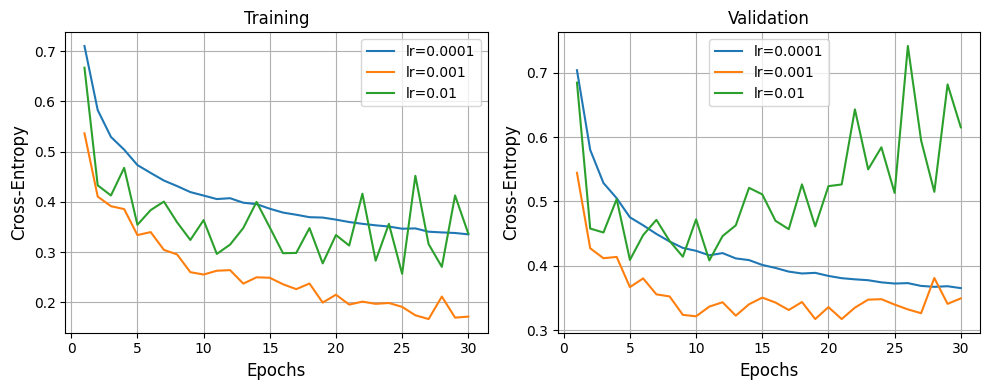

In [20]:
#RMSprop
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for gamma, hist in history_lrr.items():
    epoch = np.arange(1, len(hist["train"]) + 1)
    axes[0].plot(epoch, hist["train"], label=f"lr={gamma:g}")
    axes[1].plot(epoch, hist["val"], label=f"lr={gamma:g}")
axes[0].set_title("Training", fontsize=12)
axes[1].set_title("Validation", fontsize=12)
for ax in axes:
    ax.set_xlabel("Epochs", fontsize=12)
    ax.set_ylabel("Cross-Entropy", fontsize=12)
    ax.legend()
    ax.grid()
fig.tight_layout()
fig.savefig(figures_dir / "ffnn_rmsprop_learning_rates.pdf", bbox_inches="tight")
plt.show()

Adam presterer generelt bedre. Orker ikke å teste mer med den.

Nå tester jeg ulike noder, aktiverings funksjoner i skjulte lag. Forsatt 10 noder i output og softmax i output. Bruker epoch = 30 og Adam med learning rate 0.001. 

In [21]:
activation_functions = ['sigmoid', 'relu','leaky_relu']
hidden_layers = [1, 2, 5]
nodes = [15, 50, 100]

results_arch = {}
histories_arch = {}
print(f"activation function| number of hidden layers| nodes| Min val loss| Best epoch| Accuracy after final epoch|")
for activation in activation_functions:
    for n_layers in hidden_layers:
        for node in nodes:
            model_arch = NeuralNetwork(layer_sizes=[784] + [node]*n_layers + [10], activations=[activation]*n_layers+ [ "softmax"], cost="cross_entropy", seed=2026)
            optimizer_arch = Adam(learning_rate=best_lr)
            hist= train(model_arch, optimizer_arch, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
            key = (activation, n_layers, node)
            histories_arch[key] = hist
            y_pred = model_arch.predict(x_val)
            val_accuracy = accuracy(y_val, y_pred)

            results_arch[key] = {
                "min_val_loss": float(min(hist['val'])),
                "best_epoch": int(np.argmin(hist['val'])+ 1),
                "final_val_loss": float(hist['val'][-1]),
                "final_val_accuracy": float(val_accuracy)
            }
            print(
            f"{activation} & {n_layers} & {node} & {min(hist['val']):.4f} & "
            f"{int(np.argmin(hist['val']) + 1)} & {val_accuracy:.4f} " + r"\\")

activation function| number of hidden layers| nodes| Min val loss| Best epoch| Accuracy after final epoch|
sigmoid & 1 & 15 & 0.3643 & 30 & 0.8701 \\
sigmoid & 1 & 50 & 0.3209 & 24 & 0.8847 \\
sigmoid & 1 & 100 & 0.3049 & 28 & 0.8885 \\
sigmoid & 2 & 15 & 0.3760 & 30 & 0.8651 \\
sigmoid & 2 & 50 & 0.3138 & 28 & 0.8862 \\
sigmoid & 2 & 100 & 0.3069 & 24 & 0.8927 \\
sigmoid & 5 & 15 & 0.4971 & 30 & 0.8379 \\
sigmoid & 5 & 50 & 0.3678 & 27 & 0.8727 \\
sigmoid & 5 & 100 & 0.3382 & 22 & 0.8806 \\
relu & 1 & 15 & 0.3755 & 24 & 0.8700 \\
relu & 1 & 50 & 0.3287 & 22 & 0.8816 \\
relu & 1 & 100 & 0.3025 & 18 & 0.8966 \\
relu & 2 & 15 & 0.3691 & 22 & 0.8717 \\
relu & 2 & 50 & 0.3244 & 20 & 0.8788 \\
relu & 2 & 100 & 0.3073 & 15 & 0.8914 \\
relu & 5 & 15 & 0.3591 & 22 & 0.8743 \\
relu & 5 & 50 & 0.3166 & 12 & 0.8851 \\
relu & 5 & 100 & 0.3111 & 13 & 0.8927 \\
leaky_relu & 1 & 15 & 0.3736 & 28 & 0.8701 \\
leaky_relu & 1 & 50 & 0.3230 & 22 & 0.8866 \\
leaky_relu & 1 & 100 & 0.3078 & 18 & 0.8934 \\
l

In [22]:
best_key = min(results_arch, key=lambda k: results_arch[k]['min_val_loss'])
best_act, best_layers, best_nodes = best_key
best_sizes = [784] + [best_nodes] * best_layers + [10]
best_acts = [best_act] * best_layers + ["softmax"]
print(f"Best (Activation function, number of hidden layers, number of nodes per layer):", best_key)
print(results_arch[best_key])

Best (Activation function, number of hidden layers, number of nodes per layer): ('relu', 1, 100)
{'min_val_loss': 0.30248124719322916, 'best_epoch': 18, 'final_val_loss': 0.3128423124093846, 'final_val_accuracy': 0.8966}


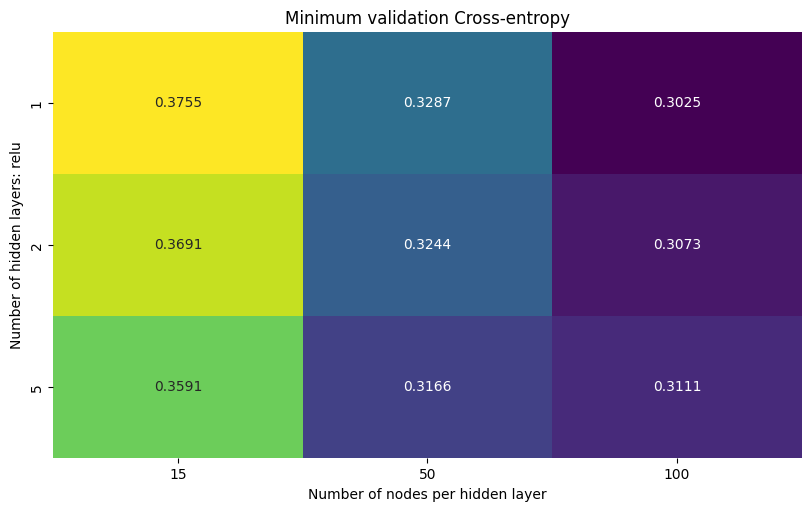

In [23]:
#Heat map for den beste kombinasjonen
cross_entropy_grid = np.array([
    [results_arch[(best_act, n_layers, node)]["min_val_loss"] for node in nodes]
    for n_layers in hidden_layers
])
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
plot_heatmap(
    values=cross_entropy_grid,
    x_labels=nodes,
    y_labels=hidden_layers,
    x_name="Number of nodes per hidden layer",
    y_name=f"Number of hidden layers: {best_act}",
    title="Minimum validation Cross-entropy",
    fmt=".4f",
    ax=ax,
    cbar=False,
)
fig.savefig(figures_dir / "ffnn_architecture_validation_heatmap.pdf", bbox_inches="tight")
plt.show()

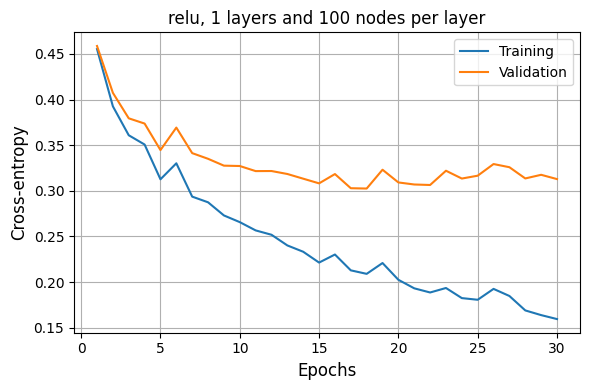

In [24]:
best_hist = histories_arch[best_key]
epochs = np.arange(1, len(best_hist["train"]) + 1)
best_epoch = results_arch[best_key]["best_epoch"]
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs, best_hist["train"], label="Training")
ax.plot(epochs, best_hist["val"], label="Validation")
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Cross-entropy", fontsize=12)
ax.set_title(f"{best_act}, {best_layers} layers and {best_nodes} nodes per layer", fontsize=12)
ax.legend()
ax.grid()
fig.tight_layout()
fig.savefig(figures_dir / "ffnn_best_architecture_loss.pdf", bbox_inches="tight")
plt.show()

Undersøker lambda

In [25]:
lambdas = [0.0, 1e-4, 1e-3, 1e-2]
results_l = {}
histories_l = {}
print(f"lambda| Min val loss| Best epoch| Accuracy after final epoch|")
for lam in lambdas:
    model_l = NeuralNetwork(layer_sizes=best_sizes, activations=best_acts, 
                            cost="cross_entropy", l1=0.0, l2=lam, seed=2026)
    optimizer_l = Adam(learning_rate=best_lr)
    hist_l = train_classification(model_l, optimizer_l, X=x_train, y=y_train_oh, epochs=30, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)
    histories_l[lam] = hist_l
    y_pred = model_l.predict(x_val)
    val_accuracy_l = accuracy(y_val, y_pred)
    
    results_l[lam] = {
                    "min_val_loss": float(min(hist_l['val'])),
                    "best_epoch": int(np.argmin(hist_l['val'])+ 1),
                    "final_val_loss": float(hist_l['val'][-1]),
                    "final_val_accuracy": float(val_accuracy_l)
                }
    print(f"{lam:g} & {min(hist_l['val']):.4f} & "
    f"{np.argmin(hist_l['val']) + 1} & {val_accuracy_l:.4f} " + r"\\")

lambda| Min val loss| Best epoch| Accuracy after final epoch|
0 & 0.3025 & 18 & 0.8966 \\
0.0001 & 0.3024 & 18 & 0.8961 \\
0.001 & 0.3255 & 22 & 0.8826 \\
0.01 & 0.4638 & 18 & 0.8360 \\


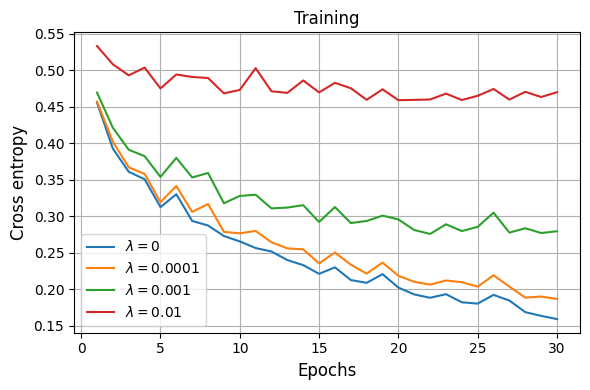

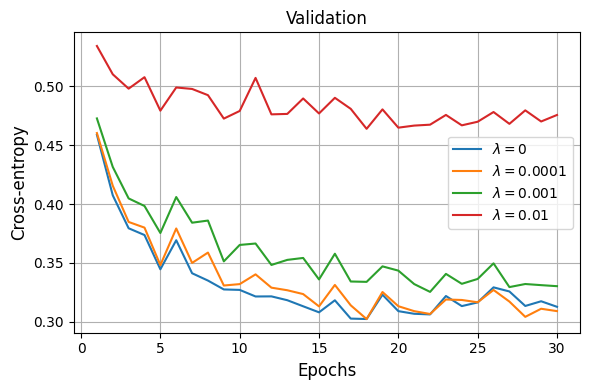

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
for lam, hist_l in histories_l.items():
    epoch = np.arange(1, len(hist_l["train"]) + 1)
    ax.plot(epoch, hist_l["train"], label=rf"$\lambda={lam:g}$")
ax.set_title("Training", fontsize=12)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Cross entropy", fontsize=12)
ax.legend()
ax.grid()
fig.tight_layout()
fig.savefig(figures_dir / "ffnn_l2_training_loss.pdf", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 4))
for lam, hist_l in histories_l.items():
    epoch = np.arange(1, len(hist_l["val"]) + 1)
    ax.plot(epoch, hist_l["val"], label=rf"$\lambda={lam:g}$")
ax.set_title("Validation", fontsize=12)
ax.set_xlabel("Epochs", fontsize=12)
ax.set_ylabel("Cross-entropy", fontsize=12)
ax.legend()
ax.grid()
fig.tight_layout()
fig.savefig(figures_dir / "ffnn_l2_validation_loss.pdf", bbox_inches="tight")
plt.show()

In [27]:
best_lambda = min(results_l, key=lambda lam: results_l[lam]['min_val_loss'])
print(best_lambda, results_l[best_lambda])

0.0001 {'min_val_loss': 0.3024403532782092, 'best_epoch': 18, 'final_val_loss': 0.3091717569043262, 'final_val_accuracy': 0.8961}


In [28]:
best_model = NeuralNetwork(layer_sizes=best_sizes, activations=best_acts, 
                            cost="cross_entropy", l1=0.0, l2=best_lambda, seed=2026)
best_optimizer = Adam(learning_rate=best_lr)
best_hist = train_classification(best_model, best_optimizer, X=x_train, y=y_train_oh, epochs=results_l[best_lambda]["best_epoch"], batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

y_pred = best_model.predict(x_val)
print(f"Validation accuracy: {accuracy(y_val, y_pred):.4f}")
print(f"Validation cross entropy: {best_hist['val'][-1]:.4f}")


Validation accuracy: 0.8909
Validation cross entropy: 0.3024


Trene på test set med valgt model

In [29]:
y_pred_test = best_model.predict(x_test)
y_test_oh = one_hot(y_test)
test_ce = cross_entropy(best_model.forward(x_test), y_test_oh)
print(f"Test accuracy:{accuracy(y_test, y_pred_test):.4f}")
print(f"Cross entropy: {test_ce:.4f}")

Test accuracy:0.8849
Cross entropy: 0.3262


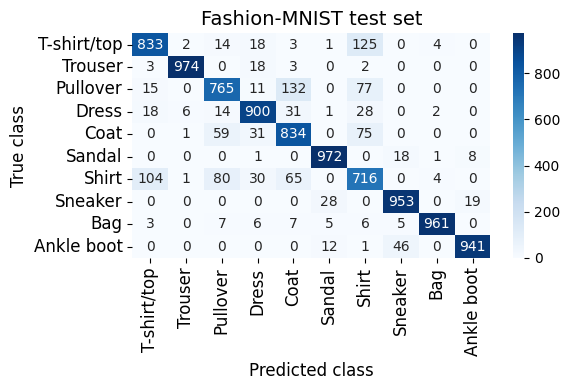

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
cm = confusion(y_test, y_pred_test)
plot_confusion(cm, class_labels=CLASS_NAMES, title="Fashion-MNIST test set", ax=ax)
ax.set_title("Fashion-MNIST test set", fontsize=14)
ax.xaxis.label.set_size(12)
ax.yaxis.label.set_size(12)
ax.tick_params(axis="both", labelsize=12)
plt.tight_layout()
fig.savefig(figures_dir / "ffnn_confusion_matrix.pdf", bbox_inches="tight")
plt.show()